# Alex Heyert Notebook
# Intro to Web Mining & Applied NLP


- Author: [Alex Heyert](https://github.com/ajaneh/)
- Repository: [nlp-01-getting-started](https://github.com/ajaneh/nlp-01-getting-started-custom/)
- Purpose: Demonstrate web mining and applied natural language processing (NLP)
- Date: 2026-10


## Section 1. Setup and Imports

Imports and configuration appear once, at the top.

WHY:
- Keeps notebooks readable and reproducible
- Mirrors professional scripts
- Makes requirements clear

This is a Markdown cell.

In [60]:
# Section 1 Python cell.

# Imports at the top of the file
# REQ: External packages must be defined in pyproject.toml
# REQ: External packages must be installed in the environment using `uv sync` command
# REQ: External packages used in this notebook must be imported here

from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import polars as pl
import requests
from wordcloud import WordCloud

print("Imports complete.")

Imports complete.


## Section 2. Retrieve a Web Page (as HTML text)

This is a Markdown cell.

In [61]:
# Section 2 Python cell

# Choose a page to analyze.

url_republican: str = (
    "https://www.presidency.ucsb.edu/documents/2024-republican-party-platform"
)
url_democratic: str = (
    "https://www.presidency.ucsb.edu/documents/2024-democratic-party-platform"
)
headers: dict[str, str] = {
    "User-Agent": "Mozilla/5.0 (compatible; NLP-Course-Example/1.0)"
}
urls = {
    "Republican": url_republican,
    "Democratic": url_democratic,
}
pages: dict[str, str] = {}

for name, url in urls.items():
    print(f"Fetching {name}: {url}")
    response = requests.get(url, headers=headers, timeout=30)
    print(f"{name}: HTTP {response.status_code}")
    response.raise_for_status()
    pages[name] = response.text
    print(f"Downloaded {len(pages[name]):,} characters")

Fetching Republican: https://www.presidency.ucsb.edu/documents/2024-republican-party-platform
Republican: HTTP 200
Downloaded 95,419 characters
Fetching Democratic: https://www.presidency.ucsb.edu/documents/2024-democratic-party-platform
Democratic: HTTP 200
Downloaded 346,433 characters


## Section 3. Parse the HTML (into a BeautifulSoup tree)

This is a Markdown cell.

In [62]:
page_text: dict[str, str] = {}

for name, page_html in pages.items():
    soup = BeautifulSoup(page_html, "lxml")
    page_text[name] = soup.get_text(" ", strip=True)

    print(f"{name}: extracted {len(page_text[name]):,} characters")
    print(page_text[name][:500])  # Preview the start

Republican: extracted 36,935 characters
2024 Republican Party Platform | The American Presidency Project Skip to main content The American Presidency Project About Search Toggle navigation Documents Guidebook Category Attributes Statistics Media Archive Presidents Analyses GIVE Documents Archive Guidebook Categories Attributes Categories Presidential (255839) Eulogies (71) Executive Orders (10879) Fireside Chats (27) Interviews (1038) Letters (4795) Miscellaneous Written (112) News Conferences (2530) Spoken Addresses and Remarks (3563
Democratic: extracted 283,848 characters
2024 Democratic Party Platform | The American Presidency Project Skip to main content The American Presidency Project About Search Toggle navigation Documents Guidebook Category Attributes Statistics Media Archive Presidents Analyses GIVE Documents Archive Guidebook Categories Attributes Categories Presidential (255839) Eulogies (71) Executive Orders (10879) Fireside Chats (27) Interviews (1038) Letters (4795) Misc

## Section 4. Extract Visible Text from the HTML

This is a Markdown cell.

In [63]:
# Section 4 Python cell

# Extract visible text from the page with get_text() method.
# separator=" " inserts spaces between chunks of text.
# strip=True removes leading and trailing whitespace.
for name, text in page_text.items():
    print(f"{name}: extracted {len(text):,} characters")
    print(text[:1000])  # Preview the start

Republican: extracted 36,935 characters
2024 Republican Party Platform | The American Presidency Project Skip to main content The American Presidency Project About Search Toggle navigation Documents Guidebook Category Attributes Statistics Media Archive Presidents Analyses GIVE Documents Archive Guidebook Categories Attributes Categories Presidential (255839) Eulogies (71) Executive Orders (10879) Fireside Chats (27) Interviews (1038) Letters (4795) Miscellaneous Written (112) News Conferences (2530) Spoken Addresses and Remarks (35633) Farewell Addresses (12) Inaugural Addresses (63) Memoranda (3505) Messages (12873) Proclamations (11160) Saturday Weekly Addresses (1639) State Dinners (266) State of the Union Addresses (101) State of the Union Written Messages (140) Statements (14723) Vetoes (1230) Citations (13241) Written Presidential Orders (50878) Remarks by Administration Officials (190) Elections and Transitions (50266) Campaign Documents (23622) Convention Speeches (128) Debate

## Section 5. Clean the Text (split, lowercase, remove punctuation, remove filler words)

In [64]:
# Section 5 Python cell

# Split the text into words and don;t include common words
stop_words = {
    # Prepositions & Conjunctions
    "from",
    "that",
    "their",
    "with",
    "for",
    "at",
    "by",
    "in",
    "on",
    "and",
    "but",
    "or",
    # Political/Modal Fillers ("will", "shall", "would", etc.)
    "will",
    "would",
    "shall",
    "should",
    "going",
    "gonna",
    "must",
    "can",
    "could",
    "have",
    "also",
    # Pronouns & Articles
    "the",
    "a",
    "an",
    "this",
    "these",
    "those",
    "they",
    "them",
    "we",
    "us",
    "our",
    "ours",
    "president",
}
clean_words: dict[str, list[str]] = {}
for name, text in page_text.items():
    words = text.split()
    # Convert to lowercase
    words = [w.lower() for w in words]
    # Remove punctuation and short tokens
    clean_words[name] = [
        w.strip(".,:;!?()[]\"'") for w in words if len(w) > 3 and w not in stop_words
    ]

# Print the first 20 words and the total number of words for each page
for name, words in clean_words.items():
    print(f"{name}:")
    print(words[:20])
    print(f"Total words: {len(words)}")

Republican:
['2024', 'republican', 'party', 'platform', 'american', 'presidency', 'project', 'skip', 'main', 'content', 'american', 'presidency', 'project', 'about', 'search', 'toggle', 'navigation', 'documents', 'guidebook', 'category']
Total words: 3464
Democratic:
['2024', 'democratic', 'party', 'platform', 'american', 'presidency', 'project', 'skip', 'main', 'content', 'american', 'presidency', 'project', 'about', 'search', 'toggle', 'navigation', 'documents', 'guidebook', 'category']
Total words: 26577


## Section 6. Build a Frequency Table (Polars)


This is a Markdown cell.

In [65]:
# Section 6 Python cell

# For working with tabular data,
# Polars is faster and smaller than pandas,
# has a more modern API, and the concepts are similar.

# Create a Polars DataFrame (df) with one row per word with a column named "word".
# Give each party it's own DataFrame for clarity.
df_dict: dict[str, pl.DataFrame] = {}
for name, words in clean_words.items():
    df_dict[name] = pl.DataFrame({"word": words})

# Group by word, count occurrences, and sort from most common to least common.
# This is a powerful pattern for counting and summarizing data in Polars.
# Function chain: group_by() -> len() -> sort()
republican_freq_df: pl.DataFrame = (
    df_dict["Republican"].group_by("word").len().sort("len", descending=True)
)

print("Top 20 most frequent words Republican speech:")
print(republican_freq_df.head(20))

Top 20 most frequent words Republican speech:
shape: (20, 2)
┌─────────────┬─────┐
│ word        ┆ len │
│ ---         ┆ --- │
│ str         ┆ u64 │
╞═════════════╪═════╡
│ american    ┆ 79  │
│ republicans ┆ 71  │
│ america     ┆ 28  │
│ restore     ┆ 25  │
│ people      ┆ 23  │
│ …           ┆ …   │
│ energy      ┆ 18  │
│ states      ┆ 17  │
│ policies    ┆ 16  │
│ families    ┆ 16  │
│ illegal     ┆ 16  │
└─────────────┴─────┘


In [66]:
democratic_freq_df: pl.DataFrame = (
    df_dict["Democratic"].group_by("word").len().sort("len", descending=True)
)
print("Top 20 most frequent words (Democratic speech):")

Top 20 most frequent words (Democratic speech):


## Section 7. Build "Most Frequent Words" Bar Chart

This is a Markdown cell.

<Figure size 1000x500 with 0 Axes>

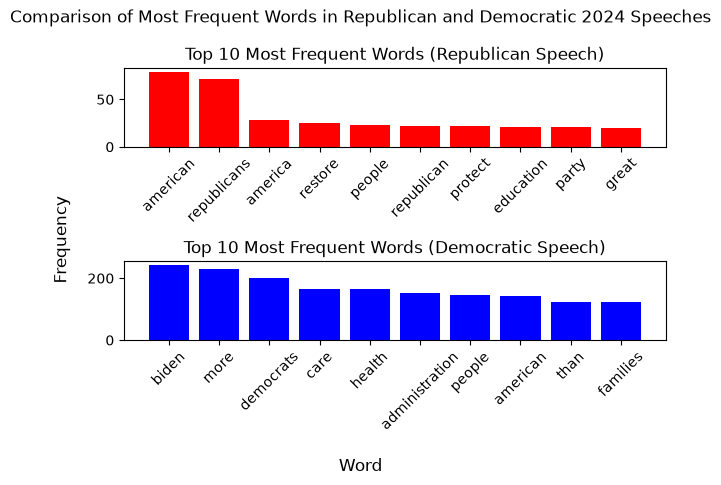

In [67]:
# Section 7 Python cell

# Use two bar charts to compare the top 10 most frequent words in the Republican and Democratic speeches.
top_republican_df: pl.DataFrame = republican_freq_df.head(10)
top_democratic_df: pl.DataFrame = democratic_freq_df.head(10)

# Make the figure size larger for better readability.
# 10 inches wide by 5 inches tall is a common size for bar charts.
plt.figure(figsize=(10, 5))

# Set the x-axis to the "word" column (the unique words).
# Set the y-axis to the "len" column (the counts).
# Establish multiplot subplots for the two bar charts.
fig, (ax1, ax2) = plt.subplots(2, 1)
ax1.bar(top_republican_df["word"], top_republican_df["len"], color="red")
ax2.bar(top_democratic_df["word"], top_democratic_df["len"], color="blue")
ax1.set_title("Top 10 Most Frequent Words (Republican Speech)")
ax2.set_title("Top 10 Most Frequent Words (Democratic Speech)")
# Set the tick labels on the x-axis
# to rotate 45 degrees for better readability,
ax1.tick_params(axis="x", labelrotation=45)
ax2.tick_params(axis="x", labelrotation=45)

fig.suptitle(
    "Comparison of Most Frequent Words in Republican and Democratic 2024 Speeches"
)
fig.supxlabel("Word")
fig.supylabel("Frequency")
plt.tight_layout()
plt.show()

## Section 8. Build a Word Cloud

This is a Markdown cell.

Sample of word frequencies:
american: 79
republicans: 71
america: 28
restore: 25
people: 23
republican: 22
protect: 22
education: 21
party: 21
great: 20


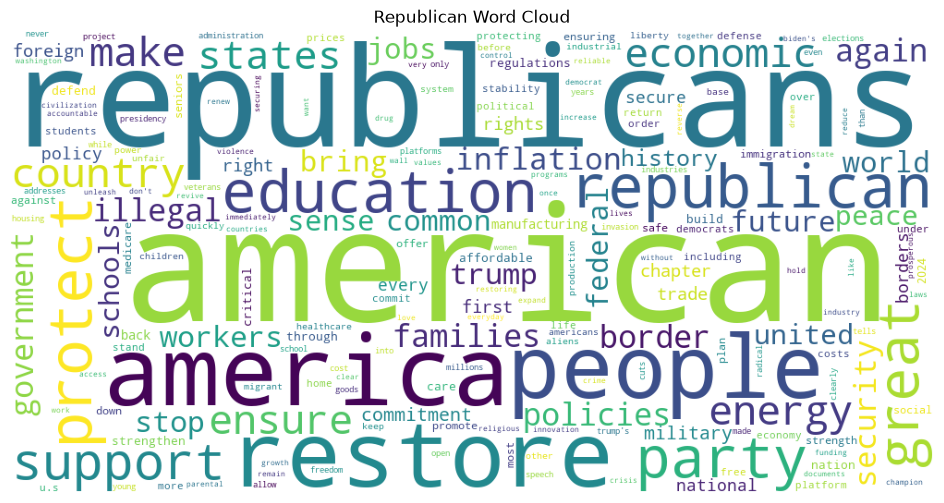

In [ ]:
# Section 8 Python cell

# For this, we want a Python dictionary
# mapping words to their frequencies.
# We can use the zip() function to combine the "word" and "len" columns into a dictionary.
# First, convert the frequency dfs to lists with to_list(),
# then zip() them together into a dictionary.
# strict=True ensures both lists are the same length.
def extract_frequencies(freq_df):
    """Extract method so we can use it for both parties."""
    return dict(zip(freq_df["word"].to_list(), freq_df["len"].to_list(), strict=True))


freq_dict: dict[str, int] = extract_frequencies(republican_freq_df)
print("Sample of word frequencies:")
for word, freq in list(freq_dict.items())[:10]:
    print(f"{word}: {freq}")

# Build a word cloud where larger words occur more frequently in the text.
# Set width and height in pixels and set the background color.
wc: WordCloud = WordCloud(width=1000, height=500, background_color="white")

# Generate the word cloud from the frequency dictionary.
wc.generate_from_frequencies(freq_dict)

# Set the figure size in inches
plt.figure(figsize=(12, 6))

# Display the word cloud image with imshow() and turn off axes for a cleaner look.
plt.imshow(wc)
plt.axis("off")
plt.title("Republican Word Cloud")
plt.show()

Sample of word frequencies (Democratic speech):
biden: 242
more: 231
democrats: 201
care: 166
health: 164
administration: 152
people: 146
american: 142
than: 123
families: 122


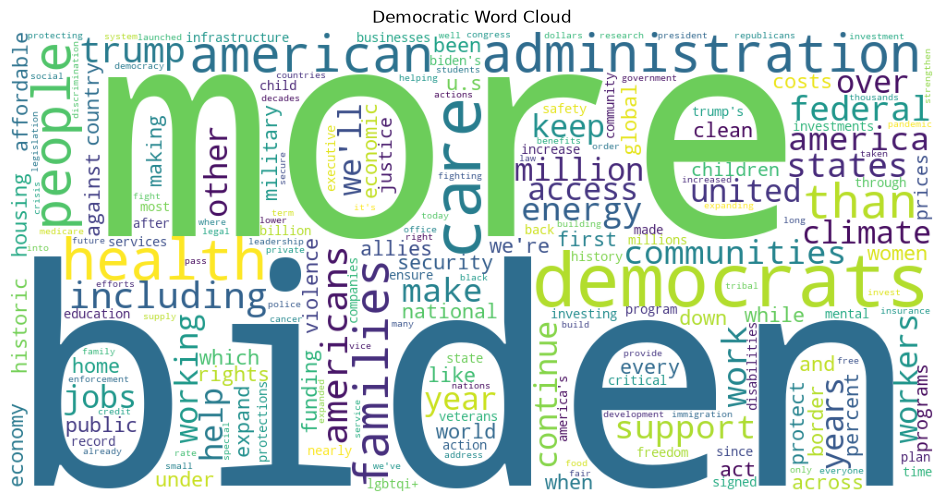

In [69]:
# Democratic word cloud
freq_dict_democratic: dict[str, int] = extract_frequencies(democratic_freq_df)
print("Sample of word frequencies (Democratic speech):")
for word, freq in list(freq_dict_democratic.items())[:10]:
    print(f"{word}: {freq}")

# Build a word cloud where larger words occur more frequently in the text.
# Set width and height in pixels and set the background color.
wc: WordCloud = WordCloud(width=1000, height=500, background_color="white")

# Generate the word cloud from the frequency dictionary.
wc.generate_from_frequencies(freq_dict_democratic)

# Set the figure size in inches
plt.figure(figsize=(12, 6))

# Display the word cloud image with imshow() and turn off axes for a cleaner look.
plt.imshow(wc)
plt.axis("off")
plt.title("Democratic Word Cloud")
plt.show()